# UTS Graf Sains Data: Python Driver Neo4j dan Rekomendasi

**Nama:** Nurus Shobah Hidayati  
**NIM:** 23031554163   
**Kelas:** Sains Data 2023 D

**Periode yang dipilih (UTC):**
- P1 (training): 1 Juni 2015 - 20 Juni 2015
- P2 (testing): 21 Juni 2015 - 30 Juni 2015

**Cara pakai notebook ini:** jalankan sel dari atas ke bawah (Shift+Enter). Sel bertanda ✏️ berisi bagian yang harus kamu isi sendiri setelah melihat hasil angkanya.

**Isi:**

0. Persiapan environment
1. Latihan (1.2 dan 1.3): tutorial driver dan dataset RetailRocket
2. Soal UTS 2.1: Wrangling dan EDA (no. 1 sampai 8)
3. Soal UTS 2.2: Analytics (KNN, Hit@5, NDCG@5)

## 0. Persiapan Environment (1.1)

Langkah yang dilakukan di terminal VS Code (Windows PowerShell):

```
python -m venv myenv              # membuat virtual environment bernama myenv
myenv\Scripts\activate            # mengaktifkan environment 
pip install -r requirements.txt   # menginstal paket yang dibutuhkan
```

Isi `requirements.txt` yang dipakai: `neo4j>=5.0`, `pandas`, `tqdm`, `scipy`, `scikit-learn`, `networkx`, `matplotlib`, `ipykernel`.

In [1]:
import sys                                   # modul sys: informasi tentang Python yang sedang berjalan
print(sys.executable)                        # lokasi python.exe; harus berakhir dengan ...\myenv\Scripts\python.exe
import neo4j                                 # mengimpor driver resmi Neo4j untuk Python
print("Versi driver neo4j:", neo4j.__version__)  # menampilkan versi driver (harus 5.x atau lebih baru)

c:\Users\Shobah\Downloads\utsgraftsada\myenv\Scripts\python.exe
Versi driver neo4j: 6.4.1


## 1. Latihan

### 1.2 Mempelajari penggunaan driver Neo4j

**Sebelum menjalankan:** buka Neo4j Desktop, pastikan instance berstatus **RUNNING** (klik **Start** kalau masih STOPPED). Kalau tidak, sel koneksi akan error `ConnectionRefusedError`.

In [ ]:
from neo4j import GraphDatabase, RoutingControl      # GraphDatabase: pembuat driver; RoutingControl: penanda baca/tulis

URI = "bolt://127.0.0.1:7687"                        # alamat server Neo4j lokal (port bawaan 7687)
AUTH = ("neo4j", "utsgraftsada123")                  # (username, password)

driver = GraphDatabase.driver(URI, auth=AUTH)        # membuat objek driver (belum benar-benar konek) 
driver.verify_connectivity()                         # tes koneksi; error jika server mati atau password salah
print("Konek ke Neo4j berhasil")                     # tanda bahwa koneksi sukses

Konek ke Neo4j berhasil


**Tutorial pertemanan (Arthur).** Fungsi `add_friend` membuat dua simpul `Person` dan satu relasi `KNOWS` di antara keduanya. `MERGE` artinya "buat kalau belum ada", sehingga tidak terjadi duplikat. Fungsi `print_friends` membaca semua teman dari seseorang.

In [6]:
def add_friend(driver, name, friend_name):                       # fungsi menambah satu pertemanan
    driver.execute_query(                                        # execute_query: kirim query Cypher ke Neo4j
        "MERGE (a:Person {name: $name}) "                        # buat/cari simpul Person dengan nama $name
        "MERGE (friend:Person {name: $friend_name}) "            # buat/cari simpul teman
        "MERGE (a)-[:KNOWS]->(friend)",                          # buat relasi berarah a -> teman
        name=name, friend_name=friend_name, database_="neo4j",   # isi parameter query; database yang dipakai: neo4j
    )

def print_friends(driver, name):                                 # fungsi mencetak teman seseorang
    records, _, _ = driver.execute_query(                        # hasil: (records, summary, keys); yang dipakai records
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "   # cari teman dari orang bernama $name
        "RETURN friend.name ORDER BY friend.name",               # kembalikan nama teman, urut abjad
        name=name, database_="neo4j", routing_=RoutingControl.READ,   # READ: ini query baca saja
    )
    for record in records:                                       # ulangi untuk tiap baris hasil
        print(record["friend.name"])                             # cetak nama teman

add_friend(driver, "Arthur", "Guinevere")                        # Arthur berteman dengan Guinevere
add_friend(driver, "Arthur", "Lancelot")                         # Arthur berteman dengan Lancelot
add_friend(driver, "Arthur", "Merlin")                           # Arthur berteman dengan Merlin
print_friends(driver, "Arthur")                                  # cetak semua teman Arthur

Guinevere
Lancelot
Merlin


**Jawaban pertanyaan pendahuluan (Checkpoint):**

1. Database yang dipakai adalah **`neo4j`** (terlihat dari parameter `database_="neo4j"`).
2. Database lain dalam satu instance diakses dengan mengganti `database_="namadb"` di Python, atau di Cypher dengan `:use namadb` / `USE namadb`. Contoh DDL: `CREATE DATABASE namadb` dan `SHOW DATABASES`. Pada tutorial 1.3 dipakai `driver.session(database="system")`.
3. Graf yang dibuat adalah graf **berarah** (directed): Arthur → Guinevere, Lancelot, Merlin lewat relasi `KNOWS`. Bentuknya graf bintang (satu pusat, tiga daun).

**CYPHER Total Reset.** Sel berikut menghapus semua relasi lalu semua simpul **per potongan 5000 baris** (`CALL {...} IN TRANSACTIONS`), supaya tidak kehabisan memori seperti pada `MATCH (n) DETACH DELETE n` yang menghapus semuanya dalam satu transaksi. Hati-hati kalau database dipakai bersama.

In [14]:
def kosongkan_database():                                               # fungsi menghapus seluruh isi database per potongan
    with driver.session(database="neo4j") as session:                   # sesi auto-commit (wajib untuk IN TRANSACTIONS)
        session.run("MATCH ()-[r]->() CALL (r) { DELETE r } IN TRANSACTIONS OF 5000 ROWS").consume()   # hapus relasi 5000 per transaksi
        session.run("MATCH (n) CALL (n) { DELETE n } IN TRANSACTIONS OF 5000 ROWS").consume()          # lalu hapus simpul 5000 per transaksi

kosongkan_database()                                                    # jalankan penghapusan
rec, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS sisa", database_="neo4j")   # cek sisa simpul
print("Database sudah bersih, sisa simpul:", rec[0]["sisa"])            # harus 0

Database sudah bersih, sisa simpul: 0


### 1.3 Dataset RetailRocket

Dataset diunduh dari Kaggle (`ecommerce-dataset.zip`), lalu `events.csv` diletakkan di folder `data/`. Berikut kolom pada `events.csv`:

| Kolom | Arti |
|---|---|
| `timestamp` | waktu kejadian, format unix epoch **dalam milidetik** |
| `visitorid` | ID unik pengunjung |
| `event` | jenis interaksi: `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk |
| `transactionid` | ID transaksi, hanya terisi jika event = `transaction` |

---
## 2. Soal UTS

## 2.1 Wrangling dan EDA

### No. 1: Menentukan 2 periode waktu

Dataset RetailRocket mencatat interaksi dari 3 Mei sampai 18 September 2015. Periode yang dipilih:

- **P1 (training):** 1 Juni 2015 00:00:00 UTC sampai 20 Juni 2015 23:59:59 UTC
- **P2 (testing):** 21 Juni 2015 00:00:00 UTC sampai 30 Juni 2015 23:59:59 UTC

Alasan: P1 lebih panjang dari P2 (data latih lebih banyak daripada data uji), dan P2 menyambung P1 sehingga banyak user di P2 yang sudah dikenal dari P1 (penting agar Hit@5 dan NDCG@5 bermakna).

In [15]:
import pandas as pd                                     # pandas: pengolah tabel data
from datetime import datetime, timezone                 # untuk mengubah tanggal menjadi timestamp

df = pd.read_csv("data/events.csv")                     # membaca seluruh events.csv ke dalam DataFrame
print("Jumlah baris:", len(df))                         # total interaksi di dataset
print("Kolom:", list(df.columns))                       # nama-nama kolom
print("Rentang data:",                                  # tanggal paling awal dan paling akhir di dataset
      pd.to_datetime(df.timestamp.min(), unit="ms"), "s/d", pd.to_datetime(df.timestamp.max(), unit="ms"))

def ke_ms(tanggal, akhir_hari=False):                   # fungsi: "YYYY-MM-DD" -> UNIX timestamp milidetik (UTC)
    dt = datetime.strptime(tanggal, "%Y-%m-%d").replace(tzinfo=timezone.utc)   # teks -> tanggal berzona UTC
    ms = int(dt.timestamp() * 1000)                     # detik -> milidetik
    return ms + 86_399_999 if akhir_hari else ms        # jika akhir hari, tambah 23:59:59.999

P1_MULAI   = ke_ms("2015-06-01")                        # awal P1
P1_SELESAI = ke_ms("2015-06-20", akhir_hari=True)       # akhir P1
P2_MULAI   = ke_ms("2015-06-21")                        # awal P2
P2_SELESAI = ke_ms("2015-06-30", akhir_hari=True)       # akhir P2

print("P1 mulai  :", P1_MULAI)                         
print("P1 selesai:", P1_SELESAI)
print("P2 mulai  :", P2_MULAI)
print("P2 selesai:", P2_SELESAI)
df.head()                                              

Jumlah baris: 2756101
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Rentang data: 2015-05-03 03:00:04.384000 s/d 2015-09-18 02:59:47.788000
P1 mulai  : 1433116800000
P1 selesai: 1434844799999
P2 mulai  : 1434844800000
P2 selesai: 1435708799999


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


### No. 2: Menerapkan filter pada `timestamp` dan menyimpan ke `.csv`

Data difilter dengan `between(mulai, selesai)` pada kolom `timestamp`. Hasilnya disimpan sebagai `events_p1.csv` dan `events_p2.csv`. **P1 dipakai membangun graf**, **P2 dipakai sebagai kunci jawaban** untuk evaluasi rekomendasi.

In [16]:
p1 = df[df.timestamp.between(P1_MULAI, P1_SELESAI)].copy()   # ambil baris yang timestamp-nya ada di rentang P1
p2 = df[df.timestamp.between(P2_MULAI, P2_SELESAI)].copy()   # ambil baris yang timestamp-nya ada di rentang P2

p1.to_csv("data/events_p1.csv", index=False)                 # simpan P1 ke file CSV (tanpa kolom indeks)
p2.to_csv("data/events_p2.csv", index=False)                 # simpan P2 ke file CSV

print("Baris P1:", len(p1), "| Baris P2:", len(p2))          # jumlah interaksi tiap periode
print("Visitor P1:", p1.visitorid.nunique(), "| Visitor P2:", p2.visitorid.nunique())   # jumlah pengunjung unik
print("Visitor di P1 dan P2:", len(set(p1.visitorid) & set(p2.visitorid)))              # pengunjung yang muncul di keduanya
print(p1.event.value_counts())                               # jumlah tiap jenis event di P1

Baris P1: 408640 | Baris P2: 201753
Visitor P1: 212988 | Visitor P2: 107636
Visitor di P1 dan P2: 6792
event
view           395078
addtocart       10189
transaction      3373
Name: count, dtype: int64


✏️ **Penjelasan:** P1 berisi 408640 baris dan P2 berisi 201753 baris. Ada 6792 visitor yang muncul di kedua periode, dan hanya mereka yang bisa dievaluasi pada bagian 2.2.

### Impor P1 ke Neo4j 
note: kode impor dari lembar soal 1.3

Alur: 

(1) `create_constraints` membuat aturan unik pada `visitorId` dan `itemId` (sekaligus membuat indeks agar `MERGE` cepat)

(2) data dibaca per potongan (*chunk*)

(3) tiap potongan dikirim ke Neo4j lewat `import_batch`. Relasi dibuat berdasarkan jenis event: `VIEWED`, `ADDED_TO_CART`, `BOUGHT`.

⚠️ Sel pertama di bawah mengosongkan database lebih dulu, karena kalau impor dijalankan dua kali relasi akan terduplikasi.

In [17]:
kosongkan_database()                                                    # bersihkan database agar impor tidak menggandakan data
print("Database dikosongkan sebelum impor")

Database dikosongkan sebelum impor


In [18]:
from tqdm import tqdm                                              # tqdm: progress bar

def create_constraints(session):                                   # membuat aturan unik
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")   # visitorId tidak boleh kembar
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")         # itemId tidak boleh kembar

def import_batch(tx, batch):                                       # mengimpor satu batch baris ke Neo4j
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """                                                            # UNWIND: pecah batch jadi baris; MERGE: buat simpul bila belum ada;
                                                                   # CALL{...}: pilih jenis relasi sesuai kolom event
    tx.run(cypher_query, batch=batch)                              # jalankan query dengan batch sebagai parameter

csv_file_path = "data/events_p1.csv"                               # file sumber: data P1 hasil filter
batch_size = 5000                                                  # jumlah baris per batch
total_rows = len(p1)                                               # total baris yang akan diimpor
total_chunks = (total_rows // batch_size) + 1                      # perkiraan jumlah batch untuk progress bar

with driver.session() as session:                                  # buka sesi ke Neo4j
    create_constraints(session)                                    # buat constraint dulu
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)      # baca CSV per potongan 5000 baris
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):   # loop tiap potongan + progress bar
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)   # NaN pada transactionid -> teks kosong
        records = chunk.to_dict(orient="records")                  # ubah potongan jadi list dictionary
        session.execute_write(import_batch, records)               # kirim ke Neo4j sebagai transaksi tulis

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 82/82 [05:37<00:00,  4.11s/it]

Proses impor berhasil.


### No. 3: Komposisi subgraph

Dua query Cypher dijalankan lewat Python API untuk menghitung jenis dan jumlah simpul serta relasi.

- `MATCH (n)` mengambil semua simpul.
- `labels(n)[0]` mengambil nama jenis (label) simpul: `Visitor` atau `Item`.
- `count(n)` menghitung jumlah simpul untuk tiap label (dikelompokkan otomatis oleh label).
- `MATCH ()-[r]->()` mengambil semua relasi, `type(r)` adalah jenisnya (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

In [19]:
q_simpul = "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah"        # hitung simpul per label
q_relasi = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah"      # hitung relasi per jenis

rec, _, _ = driver.execute_query(q_simpul, database_="neo4j")      # jalankan query simpul
tabel_simpul = pd.DataFrame([dict(r) for r in rec])                # ubah hasil jadi tabel
print(tabel_simpul, "\n")                                         # tampilkan

rec, _, _ = driver.execute_query(q_relasi, database_="neo4j")      # jalankan query relasi
tabel_relasi = pd.DataFrame([dict(r) for r in rec])                # ubah hasil jadi tabel
print(tabel_relasi)                                                # tampilkan

  jenis_simpul  jumlah
0      Visitor  212988
1         Item   94576 

    jenis_relasi  jumlah
0         VIEWED  395078
1  ADDED_TO_CART   10189
2         BOUGHT    3373


✏️ **Penjelasan:** subgraph memiliki 212988 simpul `Visitor` dan 94576 simpul `Item`, serta relasi `VIEWED` 395078, `ADDED_TO_CART` 10189, dan `BOUGHT` 3373. Relasi `VIEWED` mendominasi karena kebanyakan pengunjung hanya melihat produk dan jarang membeli.

### No. 4: Vector Space Modelling (VSM) untuk User

Setiap **User (Visitor)** direpresentasikan sebagai **vektor** yang dimensinya sebanyak jumlah item. Isi vektor adalah bobot interaksi user dengan item tersebut: `view = 1`, `addtocart = 3`, `transaction = 5`. Semua vektor disusun menjadi matriks **M** (baris = user, kolom = item) dalam format sparse karena sebagian besar isinya nol.

In [20]:
import numpy as np                                                  # operasi numerik
import scipy.sparse as sp                                           # matriks sparse (hemat memori)

BOBOT = {"view": 1, "addtocart": 3, "transaction": 5}               # bobot tiap jenis interaksi
d = p1.copy()                                                       # salinan data P1
d["bobot"] = d["event"].map(BOBOT)                                  # beri bobot sesuai jenis event
d = d.groupby(["visitorid", "itemid"], as_index=False)["bobot"].sum()   # jumlahkan bobot per pasangan (user, item)

user_cat = d["visitorid"].astype("category")                        # ubah visitorid jadi kategori (agar punya nomor baris)
item_cat = d["itemid"].astype("category")                           # ubah itemid jadi kategori (agar punya nomor kolom)
user_ids = user_cat.cat.categories.values                           # daftar visitorid asli, urut sesuai baris matriks
item_ids = item_cat.cat.categories.values                           # daftar itemid asli, urut sesuai kolom matriks

M = sp.csr_matrix(                                                  # membuat matriks sparse CSR
    (d["bobot"].values, (user_cat.cat.codes.values, item_cat.cat.codes.values)),   # (nilai, (nomor baris, nomor kolom))
    shape=(len(user_ids), len(item_ids)),                           # ukuran: jumlah user x jumlah item
)

B = (M > 0).astype(np.float32)                                      # versi biner: 1 jika user pernah berinteraksi dengan item
n_user, n_item = M.shape                                            # jumlah user dan jumlah item

print("Shape matriks M        :", M.shape, "(baris = user, kolom = item)")
print("Dimensi vektor user    :", n_item)                           # satu user = vektor sepanjang jumlah item
print("Elemen tidak nol (nnz) :", M.nnz)                            # banyaknya pasangan (user, item) yang berinteraksi
print("Kepadatan (density)    :", M.nnz / (n_user * n_item))        # nnz dibagi total sel; makin kecil makin sparse
k_user = np.asarray(B.sum(axis=1)).ravel()                          # jumlah item berbeda per user
print("Rata-rata item per user:", k_user.mean(), "| median:", np.median(k_user), "| maks:", k_user.max())

Shape matriks M        : (212988, 94576) (baris = user, kolom = item)
Dimensi vektor user    : 94576
Elemen tidak nol (nnz) : 316882
Kepadatan (density)    : 1.5731186976580326e-05
Rata-rata item per user: 1.4877927 | median: 1.0 | maks: 539.0


**Proyeksi User-User.** Dua user terhubung jika pernah berinteraksi dengan item yang sama: `UU = B · Bᵀ`. Karena jumlah user sangat besar, proyeksi digambar dari **sampel 5000 user acak** (`seed=42`), lalu hanya **50 simpul berderajat tertinggi** yang diplot dengan networkx (kalau semua diplot, laptop akan hang).

User-User (sampel): simpul = 5000 | sisi = 1546


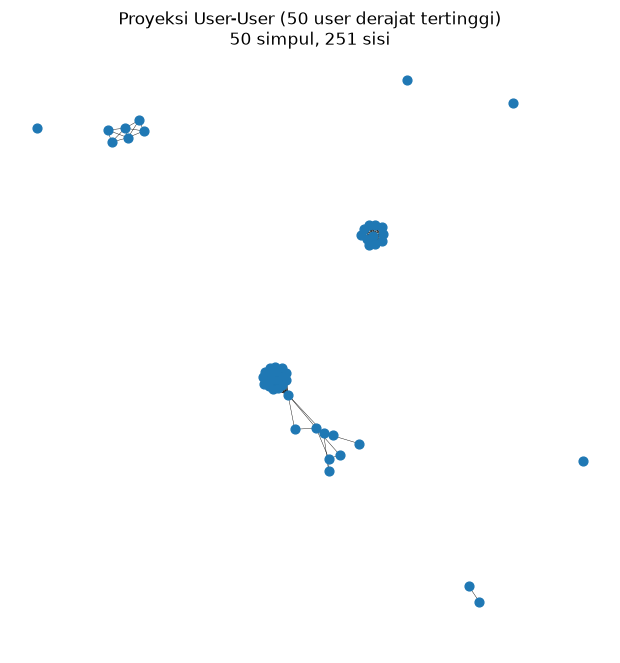

In [21]:
import networkx as nx                                               # library graf
import matplotlib.pyplot as plt                                     # library plot

rng = np.random.default_rng(42)                                     # generator acak dengan seed tetap (bisa direproduksi)
idx_u = rng.choice(n_user, size=min(5000, n_user), replace=False)   # pilih 5000 user acak
Bs = B[idx_u]                                                       # ambil baris user terpilih saja
UU = (Bs @ Bs.T).tocsr()                                            # B x B^T: elemen (a,b) = jumlah item yang sama-sama dipakai a dan b
UU.setdiag(0)                                                       # hapus hubungan user dengan dirinya sendiri
UU.eliminate_zeros()                                                # buang elemen bernilai nol dari struktur sparse
print("User-User (sampel): simpul =", UU.shape[0], "| sisi =", UU.nnz // 2)   # dibagi 2 karena graf tak berarah

def plot_top(A, judul, n_top=50):                                   # fungsi menggambar n simpul berderajat tertinggi
    G = nx.from_scipy_sparse_array(A)                               # matriks sparse -> objek graf networkx
    top = sorted(G.degree, key=lambda x: x[1], reverse=True)[:n_top]   # urutkan simpul menurut derajat, ambil teratas
    H = G.subgraph([n for n, _ in top])                             # subgraf yang hanya berisi simpul teratas itu
    plt.figure(figsize=(6, 6))                                      # ukuran gambar
    nx.draw(H, node_size=40, width=0.3)                             # gambar simpul dan sisi
    plt.title(f"{judul}\n{H.number_of_nodes()} simpul, {H.number_of_edges()} sisi")   # judul + jumlah simpul/sisi
    plt.show()                                                      # tampilkan
    return H

H_uu = plot_top(UU, "Proyeksi User-User (50 user derajat tertinggi)")

✏️ **Karakteristik VSM User :** dimensi vektor tiap user = 94576 (jumlah item), shape matriks = 212988 x 94576, kepadatan = 1.5731186976580326e-05 (sangat sparse karena tiap user hanya menyentuh sedikit item). Proyeksi User-User sampel menghasilkan 5000 simpul dan 1546 sisi. Pada plot, simpul berderajat tinggi membentuk gumpalan padat karena user-user tersebut berbagi item populer.

### No. 5: VSM untuk Item

Setiap **Item** direpresentasikan sebagai vektor yang dimensinya sebanyak jumlah user, yaitu **kolom** matriks M (atau baris dari **Mᵀ**).

**Proyeksi Item-Item:** `II = Bᵀ · B`. Dua item terhubung jika dipakai oleh user yang sama. Proyeksi digambar dari **2000 item terpopuler** (paling banyak dipakai user), lalu 50 simpul berderajat tertinggi diplot.

Shape vektor item (M^T): (94576, 212988) (baris = item, kolom = user)
Dimensi vektor item    : 212988
Kepadatan              : 1.5731186976580326e-05
Rata-rata user per item: 3.350554 | median: 1.0 | maks: 1012.0
Item-Item (2000 item terpopuler): simpul = 2000 | sisi = 99234


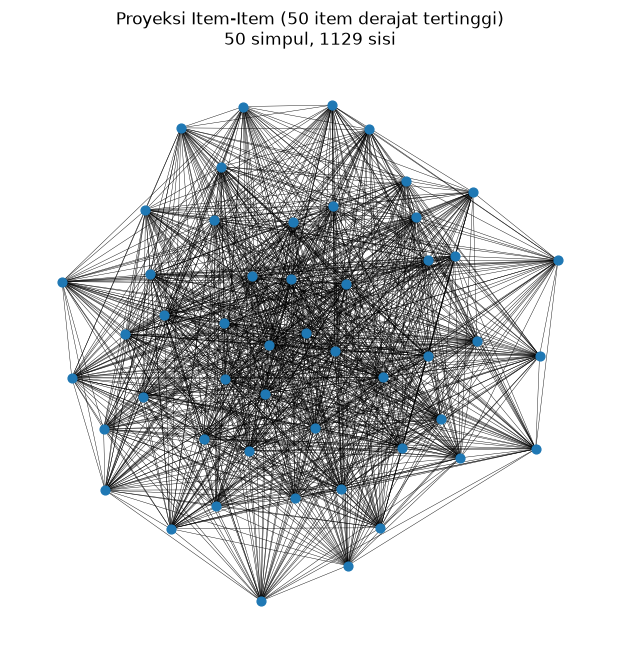

In [22]:
MT = M.T.tocsr()                                                    # transpos: baris = item, kolom = user
print("Shape vektor item (M^T):", MT.shape, "(baris = item, kolom = user)")
print("Dimensi vektor item    :", MT.shape[1])                      # satu item = vektor sepanjang jumlah user
print("Kepadatan              :", MT.nnz / (MT.shape[0] * MT.shape[1]))   # sama dengan kepadatan M

n_user_per_item = np.asarray(B.sum(axis=0)).ravel()                 # berapa user berbeda yang berinteraksi dengan tiap item
print("Rata-rata user per item:", n_user_per_item.mean(), "| median:", np.median(n_user_per_item), "| maks:", n_user_per_item.max())

top_items = np.argsort(-n_user_per_item)[:min(2000, n_item)]        # nomor kolom 2000 item terpopuler
Bi = B[:, top_items]                                                # ambil kolom item populer saja
II = (Bi.T @ Bi).tocsr()                                            # B^T x B: elemen (i,j) = jumlah user yang memakai item i dan j
II.setdiag(0)                                                       # hapus hubungan item dengan dirinya sendiri
II.eliminate_zeros()                                                # buang nol
print("Item-Item (2000 item terpopuler): simpul =", II.shape[0], "| sisi =", II.nnz // 2)

H_ii = plot_top(II, "Proyeksi Item-Item (50 item derajat tertinggi)")

✏️ **Karakteristik VSM Item :** dimensi vektor tiap item = 212988 (jumlah user), shape Mᵀ = 94576 x 212988. Satu item rata-rata disentuh 3.350554 user. Proyeksi Item-Item (2000 item terpopuler) memiliki 2000 simpul dan 99234 sisi.

### No. 6: Proyeksi mana yang lebih baik (efektif/efisien)?

Untuk membandingkan secara adil, dihitung **batas atas jumlah sisi** pada proyeksi penuh (tanpa sampel):
- User-User: satu item yang dipakai `d` user menghasilkan `d(d-1)/2` pasangan user.
- Item-Item: satu user yang memakai `k` item menghasilkan `k(k-1)/2` pasangan item.

In [23]:
d_item = n_user_per_item.astype(np.float64)                         # jumlah user per item (float64 agar tidak overflow)
k_u = k_user.astype(np.float64)                                     # jumlah item per user
sisi_uu_maks = (d_item * (d_item - 1) / 2).sum()                    # batas atas sisi proyeksi User-User penuh
sisi_ii_maks = (k_u * (k_u - 1) / 2).sum()                          # batas atas sisi proyeksi Item-Item penuh

perbandingan = pd.DataFrame({                                       # tabel perbandingan
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah simpul": [n_user, n_item],
    "Sisi maksimum (batas atas)": [int(sisi_uu_maks), int(sisi_ii_maks)],
})
perbandingan["Sisi per simpul"] = perbandingan["Sisi maksimum (batas atas)"] / perbandingan["Jumlah simpul"]
perbandingan

,Proyeksi,Jumlah simpul,Sisi maksimum (batas atas),Sisi per simpul
0,User-User,212988,3026485,14.209650
1,Item-Item,94576,1841905,19.475395


✏️ **Kesimpulan :**

Proyeksi **Item-Item** lebih baik karena jumlah simpulnya 94.576 dibanding 212988 pada User-User, dan jumlah sisinya (batas atas) 1.841.905 dibanding 3.026.485. Item-Item lebih efisien karena graf lebih kecil sehingga lebih murah disimpan dan dihitung. Proyeksi ini juga lebih efektif karena kepadatannya lebih tinggi (19,48 sisi per simpul dibanding 14,21), artinya setiap item memiliki lebih banyak hubungan yang bisa dipakai untuk menghitung similarity. Selain itu, hubungan antar produk lebih stabil dibanding perilaku user yang berubah-ubah. Maka proyeksi Item-Item **dipilih untuk perhitungan similarity di no. 7**.

### No. 7 dan 8: Perhitungan similarity pada proyeksi Item-Item

**Similarity** yang dipakai adalah **cosine similarity** antar item. Untuk dua item `i` dan `j` pada proyeksi Item-Item: `sim(i,j) = ko(i,j) / sqrt(n_i · n_j)`, dengan `ko(i,j)` = jumlah user yang memakai kedua item (elemen `II`) dan `n_i` = jumlah user yang memakai item `i`.

**Record acuan:** item dengan jumlah user terbanyak (item paling populer), supaya punya banyak tetangga.

In [24]:
ref = int(np.argmax(n_user_per_item))                               # nomor kolom item acuan = item paling populer
ref_id = int(item_ids[ref])                                         # itemid asli dari item acuan
ko = (B.T @ B[:, ref]).toarray().ravel()                            # ko[j] = jumlah user yang memakai item acuan DAN item j
sim = ko / np.sqrt(n_user_per_item[ref] * n_user_per_item)          # cosine similarity item acuan dengan semua item
sim[ref] = -1                                                       # keluarkan item acuan sendiri dari peringkat

top5 = np.argsort(-sim)[:5]                                         # nomor 5 item dengan similarity tertinggi
hasil = [(ref_id, int(item_ids[j]), float(sim[j])) for j in top5]   # daftar (item acuan, item mirip, skor)

print("Item acuan:", ref_id, "| dipakai oleh", int(n_user_per_item[ref]), "user")
for a, b, s in hasil:                                               # cetak 5 item paling mirip
    print(f"  item {b}  similarity = {s:.4f}")

Item acuan: 5411 | dipakai oleh 1012 user
  item 33030  similarity = 0.1949
  item 33956  similarity = 0.1054
  item 358234  similarity = 0.1027
  item 375492  similarity = 0.0805
  item 89143  similarity = 0.0756


**SEBELUM perhitungan similarity (no. 8).** Kondisi graf: item acuan hanya terhubung ke visitor lewat relasi interaksi, belum ada relasi `SIMILAR_TO`. 
```
MATCH (v:Visitor)-[r]->(i:Item {itemId: 5411}) RETURN v, r, i LIMIT 25
```

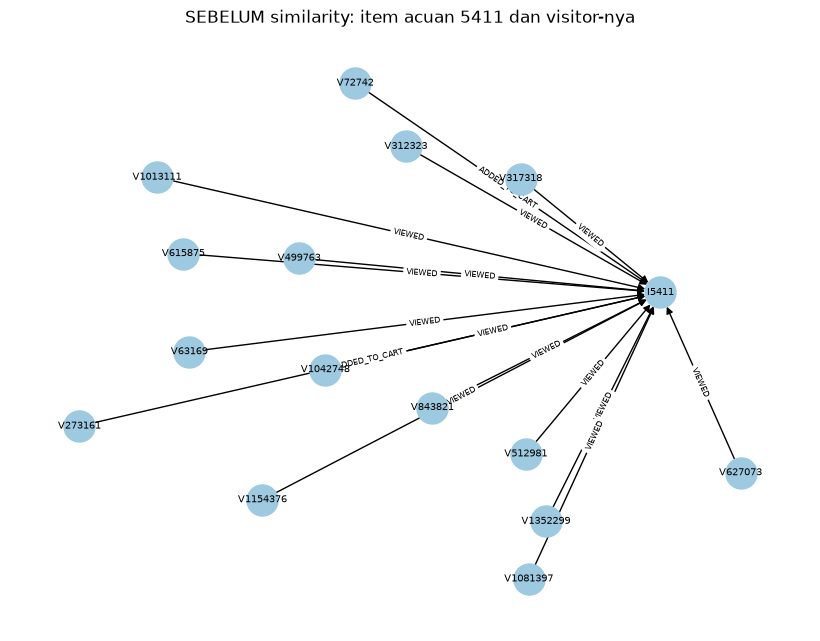

In [25]:
def gambar_graf(rec, judul):                                        # fungsi menggambar hasil query dengan networkx
    G = nx.DiGraph()                                                # graf berarah
    for r in rec:                                                   # tiap baris hasil = satu sisi
        G.add_edge(r["asal"], r["tujuan"], label=r["rel"])          # tambahkan sisi beserta nama relasinya
    pos = nx.spring_layout(G, seed=42)                              # tata letak (seed tetap agar konsisten)
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_size=500, font_size=7, node_color="#9ecae1")   # gambar simpul
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=6)   # label relasi
    plt.title(judul)
    plt.show()

q_sebelum = """
MATCH (v:Visitor)-[r]->(i:Item {itemId: $ref})
RETURN 'V' + toString(v.visitorId) AS asal, 'I' + toString(i.itemId) AS tujuan, type(r) AS rel
LIMIT 15
"""                                                                 # ambil 15 relasi visitor -> item acuan
rec, _, _ = driver.execute_query(q_sebelum, ref=ref_id, database_="neo4j")   # jalankan query dengan parameter ref
gambar_graf(rec, f"SEBELUM similarity: item acuan {ref_id} dan visitor-nya")

**No. 7b: menulis nilai similarity kembali ke graf.** Untuk tiap pasangan (item acuan, item mirip) dibuat relasi `SIMILAR_TO` dengan properti `score`.

In [26]:
def tulis_similarity(tx, rows):                                     # menulis relasi SIMILAR_TO ke Neo4j
    tx.run("""
    UNWIND $rows AS r
    MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.score = r.score
    """, rows=rows)                                                 # cari dua item, buat relasi SIMILAR_TO, isi properti score

rows = [{"a": a, "b": b, "score": s} for a, b, s in hasil]          # ubah hasil menjadi list dictionary
with driver.session() as session:                                   # buka sesi
    session.execute_write(tulis_similarity, rows)                   # jalankan penulisan sebagai transaksi tulis
print("Relasi SIMILAR_TO berhasil ditulis:", len(rows))

Relasi SIMILAR_TO berhasil ditulis: 5


**No. 7a: CYPHER untuk mendapatkan 5 record dengan similarity tertinggi.** Query ini membaca kembali nilai yang sudah tersimpan di graf, diurutkan dari skor terbesar.

In [27]:
q_top5 = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, r.score AS similarity
ORDER BY r.score DESC
LIMIT 5
"""                                                                 # urutkan skor menurun, ambil 5 teratas
rec, _, _ = driver.execute_query(q_top5, database_="neo4j")         # jalankan query
pd.DataFrame([dict(r) for r in rec])                                # tampilkan sebagai tabel

,item_acuan,item_mirip,similarity
0,5411,33030,0.194950
1,5411,33956,0.105435
2,5411,358234,0.102665
3,5411,375492,0.080496
4,5411,89143,0.075612


**SESUDAH perhitungan similarity (no. 8).** Graf kini memiliki relasi `SIMILAR_TO` dari item acuan ke 5 item terdekat. Query untuk screenshot di Neo4j Desktop:

```
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item) RETURN a, r, b
```

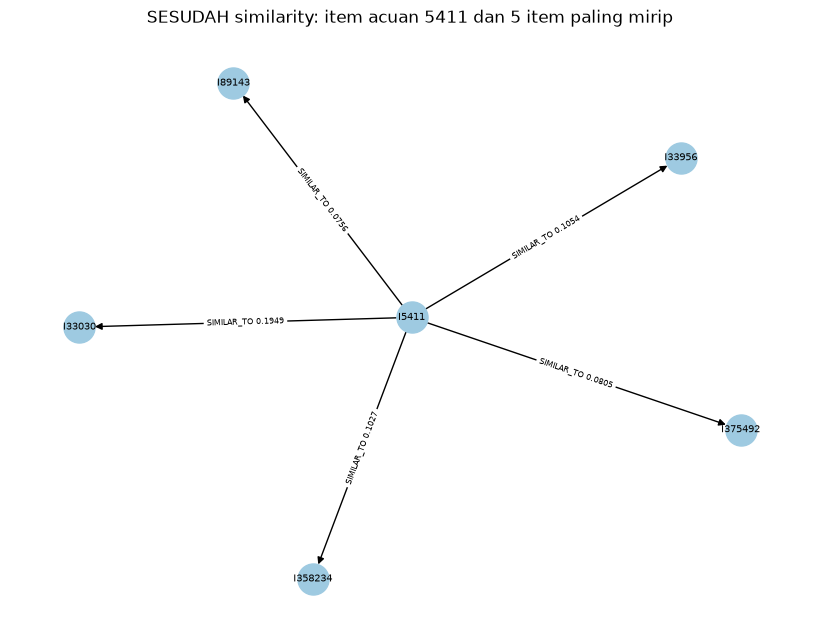

In [28]:
q_sesudah = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN 'I' + toString(a.itemId) AS asal, 'I' + toString(b.itemId) AS tujuan,
       'SIMILAR_TO ' + toString(round(r.score * 10000) / 10000.0) AS rel
"""                                                                 # ambil relasi SIMILAR_TO beserta skornya (dibulatkan)
rec, _, _ = driver.execute_query(q_sesudah, database_="neo4j")
gambar_graf(rec, f"SESUDAH similarity: item acuan {ref_id} dan 5 item paling mirip")

✏️ **Perbandingan sebelum dan sesudah:** sebelum perhitungan, item acuan (itemId 5411) hanya terhubung ke visitor lewat relasi interaksi (VIEWED, ADDED_TO_CART, BOUGHT). Sesudah perhitungan, muncul 5 relasi `SIMILAR_TO` baru yang menghubungkan item acuan ke item-item yang paling sering dipakai oleh user yang sama, dengan skor 0,0756 sampai 0,1949. Item paling mirip adalah 33030 (0,1949), disusul 33956 (0,1054), 358234 (0,1027), 375492 (0,0805), dan 89143 (0,0756).

---
## 2.2 Analytics

### No. 1a: Memilih user acak (reproducible) dan merekomendasikan dengan KNN

**Proses acak:** `random.seed(42)` lalu `random.choice` dari daftar user yang **muncul di P1 dan P2** (jika user tidak ada di P2, tidak ada kunci jawaban untuk dievaluasi). Karena seed tetap, user yang sama akan terpilih setiap kali dijalankan.

**KNN:** setiap user adalah vektor di matriks M. Dicari **k = 5 tetangga terdekat** dengan jarak cosine. Item yang direkomendasikan adalah item yang banyak disentuh para tetangga tetapi **belum pernah disentuh user tersebut** (skor = jumlah bobot interaksi tetangga).

In [29]:
import random                                                       # modul acak bawaan Python
from sklearn.neighbors import NearestNeighbors                      # algoritma KNN dari scikit-learn

random.seed(42)                                                     # seed tetap agar pilihan acak bisa direproduksi
kandidat = sorted(set(user_ids) & set(p2.visitorid))                # user yang ada di P1 DAN P2 (diurutkan agar deterministik)
user_terpilih = random.choice(kandidat)                             # pilih satu user secara acak
ui = int(np.where(user_ids == user_terpilih)[0][0])                 # nomor baris user tersebut di matriks M
print("Jumlah kandidat user:", len(kandidat), "| user terpilih:", user_terpilih)

K = 5                                                               # jumlah tetangga
knn = NearestNeighbors(n_neighbors=K + 1, metric="cosine", algorithm="brute").fit(M)   # K+1 karena user sendiri ikut terhitung
jarak, idx = knn.kneighbors(M[ui])                                  # cari tetangga terdekat dari user terpilih
tetangga = [j for j in idx[0] if j != ui][:K]                       # buang user itu sendiri, ambil 5 tetangga
print("Tetangga (visitorid):", [int(user_ids[j]) for j in tetangga])
print("Similarity tetangga :", [round(float(1 - jarak[0][list(idx[0]).index(j)]), 4) for j in tetangga])   # similarity = 1 - jarak

skor = np.asarray(M[tetangga].sum(axis=0)).ravel()                  # jumlahkan bobot interaksi kelima tetangga per item
skor[M[ui].indices] = 0                                             # item yang sudah pernah disentuh user dikeluarkan
urut = np.argsort(-skor)                                            # urutkan item dari skor tertinggi
rec5 = [int(item_ids[j]) for j in urut[:5] if skor[j] > 0]          # 5 item rekomendasi (hanya yang skornya > 0)

print("Top-5 rekomendasi   :", rec5)

Jumlah kandidat user: 6792 | user terpilih: 1082219
Tetangga (visitorid): [1373598, 1144596, 289735, 219332, 20174]
Similarity tetangga : [1.0, 1.0, 1.0, 0.7071, 0.7071]
Top-5 rekomendasi   : [316114, 313064, 90618, 88126, 67422]


### No. 1b: 3 item yang diiklankan untuk k = 5

In [30]:
iklan3 = rec5[:3]                                                   # 3 item teratas dari rekomendasi dijadikan item iklan
print("User:", user_terpilih, "| k =", K)
print("3 item yang diiklankan:", iklan3)

User: 1082219 | k = 5
3 item yang diiklankan: [316114, 313064, 90618]


### No. 2: Evaluasi Hit@5 dan NDCG@5

Kunci jawaban = item yang benar-benar disentuh user tersebut di **P2**.

- **Hit@5** = 1 jika minimal satu dari 5 item rekomendasi ada di kunci jawaban, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan `DCG = Σ rel_r / log2(r+1)` (posisi r mulai dari 1) dan IDCG adalah DCG ideal (semua posisi teratas benar).

In [31]:
kunci = set(p2.loc[p2.visitorid == user_terpilih, "itemid"])        # item yang disentuh user di P2
hits = [1 if i in kunci else 0 for i in rec5]                       # 1 jika rekomendasi ke-r ada di kunci jawaban

hit5 = int(any(hits))                                               # Hit@5
dcg = sum(h / np.log2(r + 2) for r, h in enumerate(hits))           # DCG (r mulai 0, maka penyebut log2(r+2))
idcg = sum(1 / np.log2(r + 2) for r in range(min(len(kunci), 5)))   # DCG ideal: semua posisi teratas benar
ndcg5 = dcg / idcg if idcg > 0 else 0.0                             # NDCG@5

print("Jumlah item kunci di P2:", len(kunci))
print("Rekomendasi            :", rec5)
print("Hit per posisi         :", hits)
print("Hit@5  =", hit5)
print("NDCG@5 =", round(ndcg5, 4))

Jumlah item kunci di P2: 1
Rekomendasi            : [316114, 313064, 90618, 88126, 67422]
Hit per posisi         : [0, 0, 0, 0, 0]
Hit@5  = 0
NDCG@5 = 0.0


✏️ **Interpretasi:** untuk user [ID USER] dengan k = 5, Hit@5 = 0 dan NDCG@5 = 0,0. Lima item yang direkomendasikan (316114, 313064, 90618, 88126, 67422) tidak ada yang cocok dengan item yang disentuh user tersebut di P2. Pada P2 user ini hanya menyentuh 1 item, sehingga peluang rekomendasi tepat sasaran memang kecil di antara ribuan item yang ada. Nilai 0 tidak berarti sistem salah, tetapi menunjukkan bahwa evaluasi pada satu user sangat sensitif dan di data e-commerce user jarang membuka kembali item yang direkomendasikan dalam periode pendek. 

In [32]:
driver.close()                                                      # menutup koneksi ke Neo4j setelah semua selesai
print("Koneksi ditutup")

Koneksi ditutup
